# Reto 1 (bis) · Tratamiento de valores nulos

**Objetivo:** tratar los nulos **columna a columna**, según lo que significa cada variable, y generar un CSV limpio.

No existe una receta única. Rellenar con la media o con la moda "porque sí" es el error más habitual, y aquí se vería muy claro:
si a un coche cuyo motor desconocemos le ponemos `COMBUSTION`, estamos **inventando** un dato para 134.000 filas.

## Principios que seguimos en todo el cuaderno

1. **Primero entender por qué falta el dato.** Un nulo puede significar cosas muy distintas:
   - *Falta de información recuperable* (se puede deducir de otras columnas).
   - *Falta estructural* (el dato no existe: un coche sin telemetría no tiene "velocidad media").
   - *Falta no aleatoria* (faltar ya es información: el género falta más en usuarios secundarios).
2. **Si el valor se puede deducir de otras columnas, se deduce**, pero solo con reglas que **validamos** escondiendo valores que sí conocemos y comprobando si los acertamos.
3. **Si no se puede deducir con fiabilidad, no se inventa**: se crea una categoría `UNKNOWN` (variables categóricas) o se imputa con la mediana de un grupo comparable **y se marca con una columna indicadora** (variables numéricas).
4. **Todo lo que se imputa queda marcado** con una columna `*_imputed` o `has_*_data`, para poder filtrarlo después.

## Contenido

0. Carga y panorama de nulos · herramientas de imputación
1. Variables del vehículo: `vehicle_type`, `model_class`, `engine_concept`, `fuel_type`, `date_of_first_registration`
2. Variables del cliente: `gender_derived`, `months_as_mb_customer`
3. Variables de la zona: `zipcode` y las socioeconómicas
4. Telemetría de conducción
5. Resultado: tabla resumen por columna, comprobaciones y guardado del CSV limpio

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

## 0. Carga y panorama de nulos

In [2]:
raw = pd.read_csv(CSV, low_memory=False, dtype={"zipcode": str})
raw = raw.drop(columns="Unnamed: 0")   # índice exportado del DataFrame original: no es un dato, se elimina
df = raw.copy()
print(f"{len(df):,} filas · {df.shape[1]} columnas")

nulos = raw.isna().sum()
panorama = pd.DataFrame({"nulos": nulos, "% nulos": (nulos / len(raw) * 100).round(2)})
panorama = panorama[panorama.nulos > 0].sort_values("nulos", ascending=False)
print(f"Columnas con nulos: {len(panorama)} de {raw.shape[1]}")
panorama

302,850 filas · 38 columnas
Columnas con nulos: 23 de 38


,nulos,% nulos
trip_distance_average,185857,61.37
speed_average,182382,60.22
speed_mode,181159,59.82
speed_all_counter,181159,59.82
speed_median,181159,59.82
fuel_consumption_average,180725,59.67
trip_distance_mode,179830,59.38
trip_distance_median,179830,59.38
trip_distance_all_counter,179830,59.38
fuel_type,178745,59.02


Se ven cuatro familias de columnas con nulos, y cada una se trata con una lógica distinta:

| Familia | Columnas | Idea |
|---|---|---|
| Vehículo | `vehicle_type`, `model_class`, `engine_concept`, `fuel_type`, `date_of_first_registration` | Se pueden **deducir** de otras columnas del propio vehículo |
| Cliente | `gender_derived`, `months_as_mb_customer` | Hay que ver si el nulo es aleatorio o informativo |
| Zona | `zipcode`, poder adquisitivo, población, hogares | Faltan **en bloque** (sin código postal asociado) |
| Telemetría | `trip_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average` | Falta **estructural**: el coche no envía datos |

### Herramientas de imputación (se usan varias veces)

Para deducir valores categóricos usamos una **cascada de reglas ordenadas de más a menos precisa**:

1. **Reglas deterministas** (p. ej. el nombre empieza por `EQ` → eléctrico). Solo se usan si, comprobadas sobre los datos conocidos, aciertan ≥ 98 %.
2. **Tablas de consulta aprendidas de los propios datos**: "para los coches con este nombre y este año, ¿qué valor tiene casi siempre el resto?". Cada nivel solo se acepta si ese valor se repite **muy a menudo** (*pureza*) y en **suficientes filas** (*soporte*). Si no, se pasa al siguiente nivel.
3. Si ninguno es fiable → `UNKNOWN`. **No se adivina.**

Después **validamos** la cascada: escondemos el 20 % de los valores que sí conocemos, los imputamos con el resto y medimos el acierto. Se hace de dos maneras:
- *Aleatoria*: esconde filas al azar (optimista: otros coches iguales siguen visibles).
- *Por grupo*: esconde **todos** los coches de un mismo nombre (realista para modelos nunca vistos con el dato).

In [3]:
def make_key(d, cols):
    """Clave de agrupación 'a|b|c'. Si falta cualquier componente (o vale UNKNOWN) la clave es nula."""
    k = None
    for c in cols:
        s = d[c]
        if pd.api.types.is_float_dtype(s):
            s = s.astype("Int64")
        s = s.astype("string")
        s = s.mask(s == "UNKNOWN")
        k = s if k is None else k + "|" + s
    return k


def fit_lookup(train, key_cols, target, min_n, min_purity):
    """Para cada clave: valor más frecuente del target, solo si aparece >= min_n veces y con pureza >= min_purity."""
    tmp = pd.DataFrame({"k": make_key(train, key_cols), "t": train[target]}).dropna()
    cnt = tmp.groupby(["k", "t"]).size().rename("c").reset_index()
    cnt["n"] = cnt.groupby("k")["c"].transform("sum")
    top = cnt.sort_values(["k", "c"], ascending=[True, False]).drop_duplicates("k")
    top["purity"] = top["c"] / top["n"]
    ok = top[(top["n"] >= min_n) & (top["purity"] >= min_purity)]
    return dict(zip(ok["k"], ok["t"]))


def cascade_impute(d, target, levels, rules=()):
    """Rellena los nulos de `target`. Devuelve (valores, fuente) donde fuente dice qué regla decidió cada fila."""
    out = d[target].astype(object).copy()
    todo = out.isna()
    src = pd.Series(np.where(todo, "", "original"), index=d.index, dtype=object)
    for name, fn in rules:                                   # 1) reglas deterministas
        pred = fn(d)
        m = todo & pred.notna()
        out[m], src[m] = pred[m], name
        todo = todo & ~m
    known = d[d[target].notna()]
    for name, cols, min_n, min_p in levels:                  # 2) tablas aprendidas de los datos
        lk = fit_lookup(known, cols, target, min_n, min_p)
        pred = make_key(d, cols).map(lk).astype(object)
        m = todo & pred.notna()
        out[m], src[m] = pred[m], name
        todo = todo & ~m
    out[todo], src[todo] = "UNKNOWN", "UNKNOWN (sin evidencia)"   # 3) no se adivina
    return out, src


def validate_rules(d, target, rules, min_precision=0.98):
    """Mide cada regla determinista sobre filas conocidas y devuelve solo las que superan el umbral."""
    known = d[target].notna()
    rows, kept = [], []
    for name, fn in rules:
        p = fn(d)[known]
        fired = p.notna()
        prec = (p[fired] == d.loc[known, target][fired]).mean() if fired.any() else np.nan
        rows.append({"regla": name, "filas conocidas donde se aplica": int(fired.sum()), "precisión": round(prec, 4),
                     "se usa": bool(prec >= min_precision)})
        if prec >= min_precision:
            kept.append((name, fn))
    display(pd.DataFrame(rows))
    return kept


def holdout_eval(d, target, levels, rules=(), frac=0.2, by=None, seed=0):
    """Esconde `frac` de los valores conocidos (al azar, o grupos enteros si `by`), los imputa y mide el acierto."""
    rng = np.random.default_rng(seed)
    known = d[target].notna()
    if by is None:
        hide = known & (rng.random(len(d)) < frac)
    else:
        groups = d.loc[known, by].dropna().unique()
        chosen = set(rng.choice(groups, int(len(groups) * frac), replace=False))
        hide = known & d[by].isin(chosen)
    t = d.copy()
    t.loc[hide, target] = np.nan
    pred, src = cascade_impute(t, target, levels, rules)
    r = pd.DataFrame({"real": d.loc[hide, target], "pred": pred[hide], "fuente": src[hide]})
    r["acierto"] = r["real"] == r["pred"]
    dec = r[r.fuente != "UNKNOWN (sin evidencia)"]
    tabla = r.groupby("fuente").agg(filas=("acierto", "size"), acierto=("acierto", "mean")).round(4)
    tabla["% de filas"] = (tabla["filas"] / len(r) * 100).round(1)
    print(f"  Filas escondidas: {len(r):,} · decididas: {len(dec) / len(r):.1%} · "
          f"acierto cuando decide: {dec.acierto.mean():.2%} · quedan UNKNOWN: {1 - len(dec) / len(r):.1%}")
    return tabla


def resumen_fuentes(d_before, col, src):
    """Qué regla ha rellenado cada nulo REAL de la columna."""
    m = d_before[col].isna()
    t = src[m].value_counts().rename("filas").to_frame()
    t["%"] = (t["filas"] / m.sum() * 100).round(1)
    return t

---
## 1. Variables del vehículo

### 1.1 `date_of_first_registration` → fecha limpia (preparación)

Antes de nada convertimos la fecha a tipo fecha. Hay 2 matriculaciones de **1987** en una base de coches conectados: un valor imposible,
así que se tratan como nulo. Guardamos el **año original** porque lo usarán otras deducciones (el motor de un coche depende mucho del año en que salió).

In [4]:
df["reg_date_orig"] = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
absurdas = df.reg_date_orig < "2000-01-01"
print(f"Fechas anteriores a 2000 (se pasan a nulo): {absurdas.sum()}")
df.loc[absurdas, "reg_date_orig"] = pd.NaT
df["reg_year"] = df.reg_date_orig.dt.year
print(f"Nulos de fecha tras esta limpieza: {df.reg_date_orig.isna().sum():,} ({df.reg_date_orig.isna().mean():.2%})")

Fechas anteriores a 2000 (se pasan a nulo): 2


Nulos de fecha tras esta limpieza: 4,184 (1.38%)


### 1.2 `vehicle_type` (0,3 % de nulos) → `UNKNOWN`

Es el nombre comercial del coche (`C 200 d`, `GLE 450 4MATIC`…). Es un **texto descriptivo único**: no se puede reconstruir a partir de otras columnas
(`model_class` dice "Citan" pero no qué variante exacta). Inventar un nombre sería falsificar; se marca como `UNKNOWN`.

Esos coches **no pierden información importante**: conservan `model_series`, `model_class` y `product_group`.

In [5]:
m = df.vehicle_type.isna()
print(f"vehicle_type nulo: {m.sum():,} filas")
print("Clases de esos coches (siguen informadas):", df.loc[m, "model_class"].value_counts(dropna=False).head(5).to_dict())
df["vehicle_type"] = df["vehicle_type"].fillna("UNKNOWN")
# Prefijo del nombre (p. ej. 'GLC 300 de 4MATIC' -> 'GLC'): sirve de pista para deducir la clase
df["type_prefix"] = (df.vehicle_type.str.replace(r"^(?:MERCEDES-)?AMG\s+", "", regex=True).str.split().str[0])

vehicle_type nulo: 922 filas
Clases de esos coches (siguen informadas): {'Citan': 878, 'C-Class': 32, 'S-Class': 11, 'SL-Class': 1}


### 1.3 `model_class` (1,1 % de nulos) → se deduce del nombre del coche

La clase (GLC-Class, C-Class…) es casi una consecuencia del nombre: un `GLC 400 4MATIC` es un GLC. Pero **no usamos una regla escrita a mano**:
dejamos que los datos digan, para cada nombre (o prefijo de nombre), qué clase tiene el resto de coches. Se prueba primero el nombre exacto
y, si no hay datos suficientes, el prefijo. Si ninguno es fiable → `UNKNOWN`.

In [6]:
MC_LEVELS = [
    ("nombre exacto del coche", ["vehicle_type"], 3, 0.95),
    ("prefijo del nombre",      ["type_prefix"], 20, 0.90),
]
print("Validación aleatoria:");        display(holdout_eval(df, "model_class", MC_LEVELS))
print("Validación por nombre de coche (modelos nunca vistos):"); display(holdout_eval(df, "model_class", MC_LEVELS, by="vehicle_type"))

Validación aleatoria:


  Filas escondidas: 60,096 · decididas: 86.3% · acierto cuando decide: 99.85% · quedan UNKNOWN: 13.7%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),8218,0.0000,13.7
nombre exacto del coche,51800,0.9986,86.2
prefijo del nombre,78,0.9103,0.1


Validación por nombre de coche (modelos nunca vistos):


  Filas escondidas: 68,599 · decididas: 64.7% · acierto cuando decide: 100.00% · quedan UNKNOWN: 35.3%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),24223,0.0,35.3
prefijo del nombre,44376,1.0,64.7


In [7]:
before = df.copy()
df["model_class_imputed"] = df.model_class.isna()
df["model_class"], src = cascade_impute(df, "model_class", MC_LEVELS)
print("¿Qué regla rellenó cada nulo real?")
resumen_fuentes(before, "model_class", src)

¿Qué regla rellenó cada nulo real?


,filas,%
prefijo del nombre,2674,79.4
nombre exacto del coche,695,20.6


Casi todos los nulos se recuperan con alta fiabilidad. Los que no, quedan como `UNKNOWN` en lugar de adivinar.

### 1.4 `engine_concept` (44 % de nulos) → deducción validada, **nunca "combustión por defecto"**

Es la columna más delicada: casi la mitad está vacía, y un coche sin dato **no es** necesariamente de combustión (puede ser eléctrico o híbrido).

**Lo que sabemos de los datos:**
- La motorización de un coche depende de su **nombre** y de su **año**: el mismo `GLC 220 d 4MATIC` es `COMBUSTION` en un año y `MILD_HYBRID` en otro.
  Si juntamos nombre + año, el valor se repite casi siempre (lo comprobamos abajo).
- Algunos nombres delatan la motorización: `EQ…` (EQA, EQE, EQS…) son eléctricos y un sufijo `e`/`de` (`C 300 e`, `GLC 300 de`) indica híbrido enchufable.

**Cascada** (de más a menos fiable):

| Nivel | Qué mira | Mínimo exigido |
|---|---|---|
| Regla `EQ…` → eléctrico | Nombre | precisión ≥ 98 % comprobada |
| Regla `e`/`de` → híbrido enchufable | Nombre | precisión ≥ 98 % comprobada |
| Nombre + año | Qué motor tienen los demás con ese nombre y año | pureza 95 %, ≥ 5 coches |
| Nombre | Idem solo con el nombre | pureza 90 %, ≥ 20 coches |
| Serie + año | Idem con el número de serie | pureza 90 %, ≥ 20 coches |
| Clase + año | Idem con la clase | pureza 90 %, ≥ 20 coches |
| Nada fiable | → `UNKNOWN` | |

In [8]:
# ¿Cuánto determina (nombre, año) el motor? (sobre los coches con motor conocido)
k = df[df.engine_concept.notna()]
for cols in (["vehicle_type"], ["vehicle_type", "reg_year"]):
    g = k.dropna(subset=cols).groupby(cols).engine_concept
    pur = g.agg(lambda s: s.value_counts(normalize=True).iloc[0]); n = g.size()
    print(f"Pureza media (ponderada por nº de coches) usando {cols}: {(pur * n).sum() / n.sum():.1%}")

Pureza media (ponderada por nº de coches) usando ['vehicle_type']: 95.5%

Pureza media (ponderada por nº de coches) usando ['vehicle_type', 'reg_year']: 99.7%


In [9]:
EQ_RE = r"^(?:MERCEDES-)?(?:AMG\s+)?EQ[A-Z]"
PHEV_RE = r"(?<=\d)\s?d?e\b"      # '... 300 e', '... 300 de 4MATIC'

def _rule(regex, value):
    return lambda d: pd.Series(np.where(d.vehicle_type.str.contains(regex, regex=True), value, None), index=d.index, dtype=object)

ENGINE_RULES_ALL = [("regla: nombre EQ... -> ELECTRIC", _rule(EQ_RE, "ELECTRIC")),
                    ("regla: sufijo e/de -> PLUGIN_HYBRID", _rule(PHEV_RE, "PLUGIN_HYBRID"))]
ENGINE_RULES = validate_rules(df, "engine_concept", ENGINE_RULES_ALL)

ENGINE_LEVELS = [
    ("nombre + año",  ["vehicle_type", "reg_year"], 5, 0.95),
    ("nombre",        ["vehicle_type"], 20, 0.90),
    ("serie + año",   ["model_series", "reg_year"], 20, 0.90),
    ("clase + año",   ["model_class", "reg_year"], 20, 0.90),
]

,regla,filas conocidas donde se aplica,precisión,se usa
0,regla: nombre EQ... -> ELECTRIC,15764,1.0000,True
1,regla: sufijo e/de -> PLUGIN_HYBRID,19379,0.9905,True


In [10]:
print("Validación aleatoria:");        t1 = holdout_eval(df, "engine_concept", ENGINE_LEVELS, ENGINE_RULES); display(t1)
print("Validación por nombre de coche (modelos nunca vistos con motor conocido):")
t2 = holdout_eval(df, "engine_concept", ENGINE_LEVELS, ENGINE_RULES, by="vehicle_type"); display(t2)

Validación aleatoria:


  Filas escondidas: 34,025 · decididas: 98.8% · acierto cuando decide: 99.86% · quedan UNKNOWN: 1.2%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),406,0.0000,1.2
clase + año,4,1.0000,0.0
nombre,451,0.9867,1.3
nombre + año,25656,0.9999,75.4
regla: nombre EQ... -> ELECTRIC,3225,1.0000,9.5
regla: sufijo e/de -> PLUGIN_HYBRID,3898,0.9905,11.5
serie + año,385,0.9974,1.1


Validación por nombre de coche (modelos nunca vistos con motor conocido):


  Filas escondidas: 39,072 · decididas: 66.6% · acierto cuando decide: 100.00% · quedan UNKNOWN: 33.4%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),13043,0.0000,33.4
clase + año,30,0.9667,0.1
regla: nombre EQ... -> ELECTRIC,2306,1.0000,5.9
regla: sufijo e/de -> PLUGIN_HYBRID,7848,1.0000,20.1
serie + año,15845,1.0000,40.6


**Cómo leer esto:** la validación aleatoria es la cota optimista y la "por nombre" la pesimista. En ambas, **cuando la cascada decide, acierta**;
y cuando no tiene evidencia, **se queda en `UNKNOWN`** en lugar de adivinar. Ese es el comportamiento que buscamos.

In [11]:
before = df.copy()
df["engine_concept_imputed"] = df.engine_concept.isna()
df["engine_concept"], src_engine = cascade_impute(df, "engine_concept", ENGINE_LEVELS, ENGINE_RULES)
print("¿Qué regla rellenó cada nulo real de engine_concept?")
display(resumen_fuentes(before, "engine_concept", src_engine))
comp = pd.concat({"Antes (solo conocidos)": before.engine_concept.value_counts(normalize=True),
                  "Imputados": df.loc[before.engine_concept.isna(), "engine_concept"].value_counts(normalize=True)}, axis=1).mul(100).round(1)
comp

¿Qué regla rellenó cada nulo real de engine_concept?


,filas,%
nombre,33543,25.0
UNKNOWN (sin evidencia),33364,24.8
serie + año,25651,19.1
nombre + año,25510,19.0
regla: sufijo e/de -> PLUGIN_HYBRID,7924,5.9
regla: nombre EQ... -> ELECTRIC,7114,5.3
clase + año,1284,1.0


,Antes (solo conocidos),Imputados
engine_concept,,
COMBUSTION,58.4,48.4
MILD_HYBRID,16.5,15.1
PLUGIN_HYBRID,12.7,6.4
ELECTRIC,12.4,5.3
UNKNOWN,NaN,24.8


Los coches imputados **no** salen todos como combustión: la distribución resultante refleja las motorizaciones reales de cada modelo.
Los que no se han podido deducir quedan como `UNKNOWN` y se tratarán como una categoría propia.

### 1.5 `fuel_type` (59 % de nulos) → se deduce **usando el motor ya tratado**

El combustible está muy ligado a la motorización: un eléctrico siempre es `ELECTRIC`, un híbrido enchufable es `DIESEL,ELECTRIC` o `PETROL,ELECTRIC`…
Además, el nombre indica si es diésel (`220 d`, `300 de`, `CDI`). Por eso el motor entra como pista.

Nota: todos los nulos de `engine_concept` lo eran también de `fuel_type`, pero hay otros ~44.000 coches con motor conocido y combustible vacío.

In [12]:
# ¿Es diésel por el nombre? ('220 d', '300 de', 'CDI', 'BlueTEC')
DIESEL_RE = r"(?<=\d)\s?d(?:e)?\b|\bCDI\b|\bBlueTEC\b"
df["diesel_flag"] = np.where(df.vehicle_type.str.contains(DIESEL_RE, regex=True), "D", "N")
df.loc[df.vehicle_type == "UNKNOWN", "diesel_flag"] = "UNKNOWN"

FUEL_RULES_ALL = [("regla: motor ELECTRIC -> fuel ELECTRIC",
                   lambda d: pd.Series(np.where(d.engine_concept == "ELECTRIC", "ELECTRIC", None), index=d.index, dtype=object))]
FUEL_RULES_V1 = validate_rules(df, "fuel_type", FUEL_RULES_ALL)
FUEL_LEVELS_V1 = [
    ("nombre + motor",                ["vehicle_type", "engine_concept"], 5, 0.95),
    ("serie + motor + año",           ["model_series", "engine_concept", "reg_year"], 20, 0.90),
    ("clase + ¿diésel? + motor",      ["model_class", "diesel_flag", "engine_concept"], 20, 0.90),
]
print("PRIMER INTENTO · validación por nombre de coche:")
display(holdout_eval(df, "fuel_type", FUEL_LEVELS_V1, FUEL_RULES_V1, by="vehicle_type"))

,regla,filas conocidas donde se aplica,precisión,se usa
0,regla: motor ELECTRIC -> fuel ELECTRIC,20944,1.0,True


PRIMER INTENTO · validación por nombre de coche:


  Filas escondidas: 25,880 · decididas: 85.5% · acierto cuando decide: 48.49% · quedan UNKNOWN: 14.5%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),3744,0.0000,14.5
clase + ¿diésel? + motor,2979,0.3998,11.5
regla: motor ELECTRIC -> fuel ELECTRIC,4675,1.0000,18.1
serie + motor + año,14482,0.3361,56.0


**Primer intento descartado.** En modelos nunca vistos, los niveles "serie + motor + año" y "clase + diésel + motor" **fallan más de la mitad de las veces**:
dentro de una misma serie conviven versiones diésel y gasolina, y el valor mayoritario de los coches conocidos no sirve para los desconocidos.
Si no hubiéramos validado, habríamos rellenado miles de filas con un combustible equivocado.

**Segundo intento:**
- Añadimos **reglas por el nombre**, validadas como las demás: nombre diésel (`220 d`) con motor de combustión o mild-hybrid → `DIESEL`;
  nombre diésel (`300 de`) con híbrido enchufable → `DIESEL,ELECTRIC`.
- En los niveles de respaldo exigimos que coincida también **si el nombre es diésel o no** y el año, y subimos la pureza mínima al 95 %.

In [13]:
def _fuel_rule(diesel, engines, value):
    return lambda d: pd.Series(np.where((d.diesel_flag == diesel) & d.engine_concept.isin(engines), value, None),
                               index=d.index, dtype=object)

FUEL_RULES_ALL = FUEL_RULES_ALL + [
    ("regla: nombre diésel + combustión/MHEV -> DIESEL", _fuel_rule("D", ["COMBUSTION", "MILD_HYBRID"], "DIESEL")),
    ("regla: nombre diésel + PHEV -> DIESEL,ELECTRIC", _fuel_rule("D", ["PLUGIN_HYBRID"], "DIESEL,ELECTRIC")),
]
FUEL_RULES = validate_rules(df, "fuel_type", FUEL_RULES_ALL)
FUEL_LEVELS = [
    ("nombre + motor",                    ["vehicle_type", "engine_concept"], 5, 0.95),
    ("serie + ¿diésel? + motor + año",    ["model_series", "diesel_flag", "engine_concept", "reg_year"], 20, 0.95),
    ("clase + ¿diésel? + motor + año",    ["model_class", "diesel_flag", "engine_concept", "reg_year"], 20, 0.95),
]
print("SEGUNDO INTENTO · validación aleatoria:");        display(holdout_eval(df, "fuel_type", FUEL_LEVELS, FUEL_RULES))
print("SEGUNDO INTENTO · validación por nombre de coche:"); display(holdout_eval(df, "fuel_type", FUEL_LEVELS, FUEL_RULES, by="vehicle_type"))

,regla,filas conocidas donde se aplica,precisión,se usa
0,regla: motor ELECTRIC -> fuel ELECTRIC,20944,1.0,True
1,regla: nombre diésel + combustión/MHEV -> DIESEL,31676,1.0,True
2,"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",8604,1.0,True


SEGUNDO INTENTO · validación aleatoria:


  Filas escondidas: 25,010 · decididas: 97.3% · acierto cuando decide: 99.99% · quedan UNKNOWN: 2.7%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),665,0.0000,2.7
clase + ¿diésel? + motor + año,1,1.0000,0.0
nombre + motor,11644,1.0000,46.6
regla: motor ELECTRIC -> fuel ELECTRIC,4241,1.0000,17.0
"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",1780,1.0000,7.1
regla: nombre diésel + combustión/MHEV -> DIESEL,6417,1.0000,25.7
serie + ¿diésel? + motor + año,262,0.9924,1.0


SEGUNDO INTENTO · validación por nombre de coche:


  Filas escondidas: 25,880 · decididas: 77.8% · acierto cuando decide: 85.72% · quedan UNKNOWN: 22.2%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),5755,0.0000,22.2
clase + ¿diésel? + motor + año,48,0.2500,0.2
regla: motor ELECTRIC -> fuel ELECTRIC,4675,1.0000,18.1
"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",7193,1.0000,27.8
regla: nombre diésel + combustión/MHEV -> DIESEL,517,1.0000,2.0
serie + ¿diésel? + motor + año,7692,0.6312,29.7


**Resultado del segundo intento:** las tres reglas por nombre aciertan el 100 %, pero los niveles de respaldo ("serie…" y "clase…")
**siguen fallando con modelos nunca vistos**. El motivo: en un coche no diésel, el nombre no dice si es `PETROL` o `PETROL_PLUS`, y la serie tampoco.

**Decisión final:** nos quedamos solo con las reglas validadas y con "nombre + motor" (que solo actúa cuando ese mismo modelo ya se ha visto con el dato).
Lo que no se pueda decidir así queda como `UNKNOWN`. Preferimos más `UNKNOWN` antes que un combustible equivocado.

In [14]:
FUEL_LEVELS = [("nombre + motor", ["vehicle_type", "engine_concept"], 5, 0.95)]
print("VERSIÓN FINAL · validación aleatoria:");        display(holdout_eval(df, "fuel_type", FUEL_LEVELS, FUEL_RULES))
print("VERSIÓN FINAL · validación por nombre de coche:"); display(holdout_eval(df, "fuel_type", FUEL_LEVELS, FUEL_RULES, by="vehicle_type"))

VERSIÓN FINAL · validación aleatoria:


  Filas escondidas: 25,010 · decididas: 96.3% · acierto cuando decide: 100.00% · quedan UNKNOWN: 3.7%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),928,0.0,3.7
nombre + motor,11644,1.0,46.6
regla: motor ELECTRIC -> fuel ELECTRIC,4241,1.0,17.0
"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",1780,1.0,7.1
regla: nombre diésel + combustión/MHEV -> DIESEL,6417,1.0,25.7


VERSIÓN FINAL · validación por nombre de coche:


  Filas escondidas: 25,880 · decididas: 47.9% · acierto cuando decide: 100.00% · quedan UNKNOWN: 52.1%


,filas,acierto,% de filas
fuente,,,
UNKNOWN (sin evidencia),13495,0.0,52.1
regla: motor ELECTRIC -> fuel ELECTRIC,4675,1.0,18.1
"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",7193,1.0,27.8
regla: nombre diésel + combustión/MHEV -> DIESEL,517,1.0,2.0


In [15]:
before = df.copy()
df["fuel_type_imputed"] = df.fuel_type.isna()
df["fuel_type"], src_fuel = cascade_impute(df, "fuel_type", FUEL_LEVELS, FUEL_RULES)
print("¿Qué regla rellenó cada nulo real de fuel_type?")
resumen_fuentes(before, "fuel_type", src_fuel)

¿Qué regla rellenó cada nulo real de fuel_type?


,filas,%
UNKNOWN (sin evidencia),87989,49.2
regla: nombre diésel + combustión/MHEV -> DIESEL,48363,27.1
nombre + motor,32126,18.0
regla: motor ELECTRIC -> fuel ELECTRIC,7114,4.0
"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",3153,1.8


### 1.6 `date_of_first_registration` (1,4 % + 2 fechas absurdas) → mediana de la serie

La fecha de matriculación no se puede deducir exactamente, pero un modelo (serie) **se vende en una ventana de años limitada**
Imputamos la **mediana de la fecha de los demás coches de la misma serie**.

Lo **validamos** escondiendo fechas conocidas y midiendo el error en años, comparado con el rellenado ingenuo (mediana global de todos los coches).

In [16]:
epoch = pd.Timestamp("2000-01-01")
df["reg_days"] = (df.reg_date_orig - epoch).dt.days

rng = np.random.default_rng(0)
known = df.reg_days.notna()
hide = known & (rng.random(len(df)) < 0.2)
train = df[known & ~hide]
pred_series = df.loc[hide, "model_series"].map(train.groupby("model_series").reg_days.median()).fillna(train.reg_days.median())
err_series = (pred_series - df.loc[hide, "reg_days"]).abs() / 365.25
err_global = (train.reg_days.median() - df.loc[hide, "reg_days"]).abs() / 365.25
print(f"Error mediano  · mediana de la serie: {err_series.median():.2f} años · mediana global (ingenuo): {err_global.median():.2f} años")
print(f"Error medio    · mediana de la serie: {err_series.mean():.2f} años · mediana global (ingenuo): {err_global.mean():.2f} años")

Error mediano  · mediana de la serie: 1.26 años · mediana global (ingenuo): 2.25 años
Error medio    · mediana de la serie: 1.47 años · mediana global (ingenuo): 2.55 años


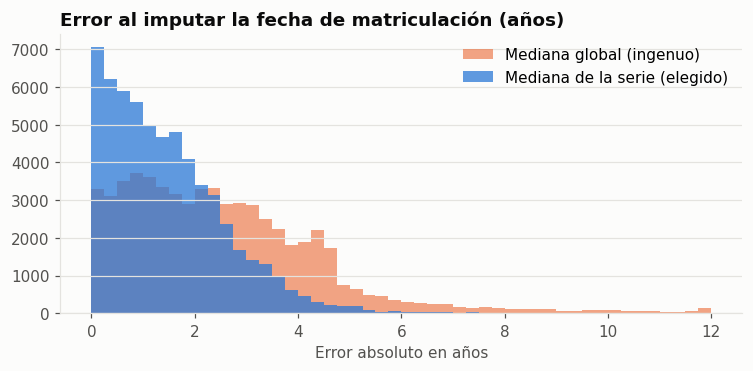

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.3))
bins = np.linspace(0, 12, 49)
ax.hist(err_global.clip(upper=12), bins=bins, alpha=.6, color=ps.SERIES[1], label="Mediana global (ingenuo)")
ax.hist(err_series.clip(upper=12), bins=bins, alpha=.75, color=ps.SERIES[0], label="Mediana de la serie (elegido)")
ax.set_title("Error al imputar la fecha de matriculación (años)"); ax.set_xlabel("Error absoluto en años"); ax.legend()
fig.savefig(FIG_DIR / "01b_error_fecha.png"); plt.show()

In [18]:
df["registration_date_imputed"] = df.date_of_first_registration.isna() | df.reg_date_orig.isna()
med_series = df.groupby("model_series").reg_days.transform("median")
df["reg_days"] = df.reg_days.fillna(med_series).fillna(df.reg_days.median())
df["date_of_first_registration"] = (epoch + pd.to_timedelta(df.reg_days.round(), unit="D")).dt.strftime("%Y-%m-%d")
df["reg_year_final"] = pd.to_datetime(df.date_of_first_registration).dt.year
print(f"Fechas imputadas: {df.registration_date_imputed.sum():,}")

Fechas imputadas: 4,184


---
## 2. Variables del cliente

### 2.1 `gender_derived` (11 %) → categoría `UNKNOWN`, **sin imputar**

El género es un dato **inferido** por Mercedes-Benz, no declarado. Antes de decidir comprobamos si los nulos son aleatorios:

In [19]:
g = raw.gender_derived.isna()
print("Distribución del género conocido:", raw.gender_derived.value_counts(normalize=True).round(3).to_dict())
tabla = pd.concat({"% nulo según rol": g.groupby(raw.role).mean(),
                   "% nulo según edad": g.groupby(raw.age_range).mean()}, axis=0).mul(100).round(1)
tabla.to_frame("% de nulos")

Distribución del género conocido: {'male': 0.83, 'female': 0.17}


% de nulos
% nulo según rol  DRIVER            4.1
                  LEGACY           11.9
                  OWNER             9.2
                  TEMP_USER        38.1
                  USER             36.2
% nulo según edad 25-34            11.9
                  35-44             8.7
                  45-54             7.1
                  55-64             5.6
                  65+              21.1
                  <25              34.3

**Los nulos no son aleatorios**: son mucho más frecuentes en usuarios secundarios (`USER`, `TEMP_USER`) y en los extremos de edad (`<25`, `65+`).
Es decir, que falte el género **ya es información** sobre el tipo de cliente.

Por eso **no** se imputa con la moda: como el 83 % de los conocidos son hombres, rellenaríamos con "hombre" a miles de personas sin saberlo,
y además atribuiríamos un género a alguien sin base. Se deja como categoría propia `UNKNOWN`.

In [20]:
df["gender_derived"] = df.gender_derived.fillna("UNKNOWN")
df.gender_derived.value_counts()

gender_derived
male       223091
female      45836
UNKNOWN     33923
Name: count, dtype: int64

### 2.2 `months_as_mb_customer` (4 filas) → mediana de clientes comparables

Solo 4 filas, que pertenecen a **2 clientes**. Los datos del cliente son constantes entre sus filas, así que no hay otra fila de la que copiar el valor.
Miramos qué tienen en común:

In [21]:
mm = raw[raw.months_as_mb_customer.isna()]
print("Vehículos actuales de esos clientes (is_current_vehicle):", mm.is_current_vehicle.value_counts().to_dict())
print("currently_connected_vehicles de esos clientes:", mm.currently_connected_vehicles.value_counts().to_dict())
comp = raw[raw.currently_connected_vehicles.isin(mm.currently_connected_vehicles.unique())]
print(f"Mediana de meses de clientes con ese mismo nº de vehículos conectados: {comp.months_as_mb_customer.median():.0f} "
      f"(mediana global: {raw.months_as_mb_customer.median():.0f})")

Vehículos actuales de esos clientes (is_current_vehicle): {False: 4}
currently_connected_vehicles de esos clientes: {0: 4}
Mediana de meses de clientes con ese mismo nº de vehículos conectados: 26 (mediana global: 39)


In [22]:
grupo_med = df.groupby("currently_connected_vehicles").months_as_mb_customer.transform("median")
n_imp = df.months_as_mb_customer.isna().sum()
df["months_as_mb_customer"] = df.months_as_mb_customer.fillna(grupo_med).fillna(df.months_as_mb_customer.median())
print(f"Imputadas {n_imp} filas con la mediana de su grupo (mismo nº de vehículos conectados)")

Imputadas 4 filas con la mediana de su grupo (mismo nº de vehículos conectados)


Ambos clientes tienen **0 vehículos conectados** (todos sus coches son antiguos). Los clientes en esa situación tienen una mediana de antigüedad
bastante menor que la global (lo vemos arriba), así que la mediana global los sesgaría. Usamos la mediana de su grupo; con 4 filas el efecto en el conjunto es mínimo.
No se añade columna indicadora: son 4 filas y quedan documentadas aquí.

---
## 3. Variables de la zona (código postal y poder adquisitivo)

Todas son datos del **código postal**. Veamos si faltan juntas:

In [23]:
cols_zona = ["zipcode", "purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur",
             "population", "number_of_households", "purchasing_power_millions_eur"]
patron = raw[cols_zona].isna().value_counts().rename("filas").reset_index()
patron.columns = [c.replace("purchasing_power_", "pp_") for c in patron.columns]
display(patron)
print("\n% de filas sin datos socioeconómicos, por país:")
print((raw.purchasing_power_per_household_eur.isna().groupby(raw.country_code).mean() * 100).round(1).to_dict())
print("\nMediana del poder adquisitivo por hogar (€) por país:")
print(raw.groupby("country_code").purchasing_power_per_household_eur.median().round(0).to_dict())

,zipcode,pp_per_inhabitant_eur,pp_per_household_eur,population,number_of_households,pp_millions_eur,filas
0,False,False,False,False,False,False,283763
1,True,True,True,True,True,True,16135
2,False,True,True,True,True,True,2879
3,False,True,True,False,False,True,73



% de filas sin datos socioeconómicos, por país:
{'AT': 8.3, 'CH': 5.1}

Mediana del poder adquisitivo por hogar (€) por país:
{'AT': 68008.0, 'CH': 115775.0}


**Hallazgos:**
- Los datos socioeconómicos faltan **todos a la vez** (o el cliente no tiene código postal, o su código postal no está en la tabla de zonas). No hay ninguna fila donde falte solo una de las variables y pueda deducirse de las otras.
- Hay **73 filas con `population = 0`**: son zonas sin datos (el poder adquisitivo también falta). Un 0 aquí es un valor falso, no una zona vacía.
- **Austria y Suiza son muy distintas** económicamente. Imputar con una mediana *global* mezclaría ambos mercados. El país **nunca es nulo**, así que se usa como grupo de referencia.

Comprobamos además que los campos están **relacionados exactamente**, para mantener la coherencia al imputar:

In [24]:
ok = raw.dropna(subset=cols_zona[1:])
rel1 = (ok.purchasing_power_per_inhabitant_eur * ok.population / 1e6) / ok.purchasing_power_millions_eur - 1
rel2 = (ok.purchasing_power_per_household_eur * ok.number_of_households / 1e6) / ok.purchasing_power_millions_eur - 1
print(f"Error relativo mediano de  millones = pp_por_habitante × población / 1e6 :   {rel1.abs().median():.1e}")
print(f"Error relativo mediano de  millones = pp_por_hogar × nº_hogares / 1e6     :   {rel2.abs().median():.1e}")

Error relativo mediano de  millones = pp_por_habitante × población / 1e6 :   5.7e-07


Error relativo mediano de  millones = pp_por_hogar × nº_hogares / 1e6     :   5.8e-07


La identidad se cumple prácticamente al céntimo (el error es solo de redondeo). Por tanto:

| Columna | Tratamiento | Por qué |
|---|---|---|
| `zipcode` | `UNKNOWN` | Es un identificador geográfico; no se puede inventar un código postal |
| `purchasing_power_per_inhabitant_eur`, `purchasing_power_per_household_eur` | Mediana **del país** | Nivel económico típico del mercado del cliente |
| `population`, `number_of_households` | Mediana **del país** (los ceros se tratan como nulos) | Tamaño típico de zona |
| `purchasing_power_millions_eur` | **Se recalcula** = pp por habitante × población / 1e6 | Mantiene la identidad exacta que cumplen los datos reales; no se imputa por separado |
| `socio_imputed` (nueva) | Marca de las filas imputadas | Para poder excluirlas o analizarlas aparte |

In [25]:
df.loc[df.population == 0, ["population", "number_of_households"]] = np.nan      # ceros falsos -> nulo
df["socio_imputed"] = df.purchasing_power_per_household_eur.isna()
for c in ["purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur", "population", "number_of_households"]:
    df[c] = df[c].fillna(df.groupby("country_code")[c].transform("median"))
# millones: se recalcula con la identidad en las filas imputadas (en las reales ya cumple)
df.loc[df.socio_imputed, "purchasing_power_millions_eur"] = (
    df.purchasing_power_per_inhabitant_eur * df.population / 1e6)[df.socio_imputed]
df["zipcode"] = df.zipcode.fillna("UNKNOWN")
print(f"Filas con datos de zona imputados: {df.socio_imputed.sum():,} ({df.socio_imputed.mean():.1%})")
df.loc[df.socio_imputed, ["country_code", "purchasing_power_per_household_eur", "population"]].drop_duplicates()

Filas con datos de zona imputados: 19,087 (6.3%)


,country_code,purchasing_power_per_household_eur,population
16,AT,68008.12,9407.0
89,CH,115775.10,6600.0


---
## 4. Telemetría de conducción (~60 % de nulos)

Columnas: `trip_distance_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average`.

Aquí el nulo **no es un dato perdido**: significa "este coche no ha enviado datos de conducción". Lo comprobamos:

In [26]:
tel_cols = ["trip_distance_average", "trip_distance_mode", "trip_distance_median", "trip_distance_all_counter",
            "operating_hours_total", "fuel_consumption_average",
            "speed_average", "speed_mode", "speed_median", "speed_all_counter"]
sin_nada = raw[tel_cols].isna().all(axis=1)
print(f"Filas sin NINGÚN dato de telemetría: {sin_nada.mean():.1%}")
con_datos = raw[tel_cols].notna().any(axis=1)
print("\n% de coches con telemetría según el año de matriculación:")
y = pd.to_datetime(raw.date_of_first_registration, errors="coerce").dt.year
print((con_datos.groupby(y).mean().loc[2010:] * 100).round(0).astype(int).to_dict())
print("\n% con telemetría según si el vehículo está activo:", (con_datos.groupby(raw.is_current_vehicle).mean() * 100).round(1).to_dict())
print("% con consumo de combustible, según motor:",
      (raw.fuel_consumption_average.notna().groupby(df.engine_concept).mean() * 100).round(1).to_dict())

Filas sin NINGÚN dato de telemetría: 51.8%

% de coches con telemetría según el año de matriculación:


{2010.0: 1, 2011.0: 4, 2012.0: 7, 2013.0: 12, 2014.0: 17, 2015.0: 23, 2016.0: 36, 2017.0: 43, 2018.0: 44, 2019.0: 50, 2020.0: 56, 2021.0: 58, 2022.0: 57, 2023.0: 55, 2024.0: 53, 2025.0: 48, 2026.0: 28}

% con telemetría según si el vehículo está activo: {False: 33.4, True: 58.3}
% con consumo de combustible, según motor: {'COMBUSTION': 46.2, 'ELECTRIC': 0.0, 'MILD_HYBRID': 48.3, 'PLUGIN_HYBRID': 42.6, 'UNKNOWN': 32.0}


**Conclusiones:**
1. **Más de la mitad de las filas no tiene ninguna telemetría**, y la presencia cae mucho en los coches antiguos (≤ 12 % antes de 2014 frente a ~55 % en 2020-2023): es una falta estructural (coches no conectables o que no comparten datos), no un error.
2. Los coches **eléctricos nunca tienen `fuel_consumption_average`**: no consumen combustible, así que el dato no *existe*; no es "desconocido".
3. Hay datos **parciales** (p. ej. velocidad pero no trayectos), así que la presencia hay que registrarla por bloque.

**Decisión: no inventar datos de conducción para coches que no los envían, pero sí dejar la tabla completa.** Para ello:
- Se crean **indicadores de presencia reales** (`has_trip_data`, `has_speed_data`, `has_hours_data`, `has_consumption_data`, `has_telemetry`) **antes** de rellenar.
- Se rellena cada tipo de columna con el criterio que tiene sentido para su naturaleza:

| Tipo de columna | Columnas | Relleno si falta | Razón |
|---|---|---|---|
| **Contadores** | `trip_distance_all_counter`, `speed_all_counter` | `0` | Son "nº de mediciones usadas": si no hay datos, el valor correcto es literalmente 0 |
| **Modas (texto)** | `trip_distance_mode`, `speed_mode` | `NO_DATA` | Son texto (a veces varias modas separadas por comas); no tiene sentido una "moda media" |
| **Horas de uso** | `operating_hours_total` | Mediana de coches del **mismo año de matriculación** | Es un acumulado: crece con la edad del coche |
| **Consumo** | `fuel_consumption_average` | Eléctricos → `0`; resto → mediana de la **misma clase** de coche | Eléctrico: no consume. Resto: depende sobre todo del tamaño del coche |
| **Medias y medianas de uso** | `trip_distance_average/median`, `speed_average/median` | Mediana de coches con **la misma motorización** | Valor típico de un coche comparable |

> **Importante:** los valores rellenados en coches sin telemetría son **valores típicos, no mediciones**. Quien use estas columnas para analizar
> hábitos de conducción debe filtrar por `has_telemetry == True`.

In [27]:
# 1) Indicadores de presencia REAL (antes de rellenar nada)
df["has_trip_data"] = df.trip_distance_median.notna()
df["has_speed_data"] = df.speed_median.notna()
df["has_hours_data"] = df.operating_hours_total.notna()
df["has_consumption_data"] = df.fuel_consumption_average.notna()
df["has_telemetry"] = df[["has_trip_data", "has_speed_data", "has_hours_data", "has_consumption_data"]].any(axis=1)
print(df[["has_trip_data", "has_speed_data", "has_hours_data", "has_consumption_data", "has_telemetry"]].mean().mul(100).round(1).to_dict())
partial = df.has_trip_data & df.trip_distance_average.isna()
print(f"\nFilas con trayectos pero sin media de distancia (hueco puntual, no estructural): {partial.sum():,}")

{'has_trip_data': 40.6, 'has_speed_data': 40.2, 'has_hours_data': 42.4, 'has_consumption_data': 40.3, 'has_telemetry': 48.2}

Filas con trayectos pero sin media de distancia (hueco puntual, no estructural): 6,027


In [28]:
def fill_group_median(d, col, by_levels):
    """Rellena con la mediana del grupo (probando grupos de más específico a más general; último recurso: mediana global)."""
    s = d[col].copy()
    for by in by_levels:
        s = s.fillna(d.groupby(by)[col].transform("median"))
    return s.fillna(d[col].median())

# 2) Contadores -> 0 ; modas -> NO_DATA
for c in ["trip_distance_all_counter", "speed_all_counter"]:
    df[c] = df[c].fillna(0)
for c in ["trip_distance_mode", "speed_mode"]:
    df[c] = df[c].fillna("NO_DATA")

# 3) Horas de uso -> mediana del mismo año de matriculación
df["operating_hours_total"] = fill_group_median(df, "operating_hours_total", [["reg_year_final"]])

# 4) Consumo -> eléctricos 0 ; resto mediana de su clase (luego de su motorización)
ev = df.engine_concept == "ELECTRIC"
df.loc[ev, "fuel_consumption_average"] = 0.0
no_ev = df.assign(_c=df.fuel_consumption_average.where(~ev))
df["fuel_consumption_average"] = df.fuel_consumption_average.fillna(
    no_ev.groupby("model_class")["_c"].transform("median")).fillna(
    no_ev.groupby("engine_concept")["_c"].transform("median")).fillna(no_ev["_c"].median())

# 5) Medias y medianas de uso -> mediana de la misma motorización
for c in ["trip_distance_average", "trip_distance_median", "speed_average", "speed_median"]:
    df[c] = fill_group_median(df, c, [["engine_concept"]])
print("Nulos restantes en telemetría:", int(df[tel_cols].isna().sum().sum()))

Nulos restantes en telemetría: 0


---
## 5. Resultado

### 5.1 Ensamblado y comprobaciones

In [29]:
helpers = ["reg_date_orig", "reg_year", "reg_year_final", "reg_days", "type_prefix", "diesel_flag"]
clean = df.drop(columns=helpers)
orig_cols = list(raw.columns)
flag_cols = [c for c in clean.columns if c not in orig_cols]
clean = clean[orig_cols + flag_cols]

assert clean.isna().sum().sum() == 0, "quedan nulos"
assert len(clean) == len(raw)
print(f"CSV limpio: {clean.shape[0]:,} filas · {clean.shape[1]} columnas ({len(orig_cols)} originales + {len(flag_cols)} indicadores)")
print("Nulos totales:", int(clean.isna().sum().sum()))
print("\nIndicadores añadidos:", flag_cols)

CSV limpio: 302,850 filas · 48 columnas (38 originales + 10 indicadores)


Nulos totales: 0

Indicadores añadidos: ['model_class_imputed', 'engine_concept_imputed', 'fuel_type_imputed', 'registration_date_imputed', 'socio_imputed', 'has_trip_data', 'has_speed_data', 'has_hours_data', 'has_consumption_data', 'has_telemetry']


In [30]:
# Las columnas que NO tenían nulos no se han alterado
sin_nulos = [c for c in orig_cols if raw[c].isna().sum() == 0]
cambiadas = [c for c in sin_nulos if not (clean[c].astype(str).values == raw[c].astype(str).values).all()]
print("Columnas sin nulos en origen que han cambiado de valor (debería ser vacío):", cambiadas)

Columnas sin nulos en origen que han cambiado de valor (debería ser vacío): []


In [31]:
# Comparación antes / después en variables numéricas clave (no debe distorsionarse la distribución)
comp = pd.DataFrame({
    "media antes": raw[["purchasing_power_per_household_eur", "population", "months_as_mb_customer", "operating_hours_total",
                        "speed_average", "trip_distance_average"]].mean(),
    "media después": clean[["purchasing_power_per_household_eur", "population", "months_as_mb_customer", "operating_hours_total",
                            "speed_average", "trip_distance_average"]].mean(),
    "mediana antes": raw[["purchasing_power_per_household_eur", "population", "months_as_mb_customer", "operating_hours_total",
                          "speed_average", "trip_distance_average"]].median(),
    "mediana después": clean[["purchasing_power_per_household_eur", "population", "months_as_mb_customer", "operating_hours_total",
                              "speed_average", "trip_distance_average"]].median(),
}).round(2)
comp

,media antes,media después,mediana antes,mediana después
purchasing_power_per_household_eur,104766.27,104014.86,102246.51,102327.34
population,19664.85,18931.11,7132.00,7132.00
months_as_mb_customer,43.87,43.87,39.00,39.00
operating_hours_total,620.27,488.93,406.51,398.00
speed_average,48.67,49.06,49.34,49.42
trip_distance_average,16.16,14.89,14.02,14.42


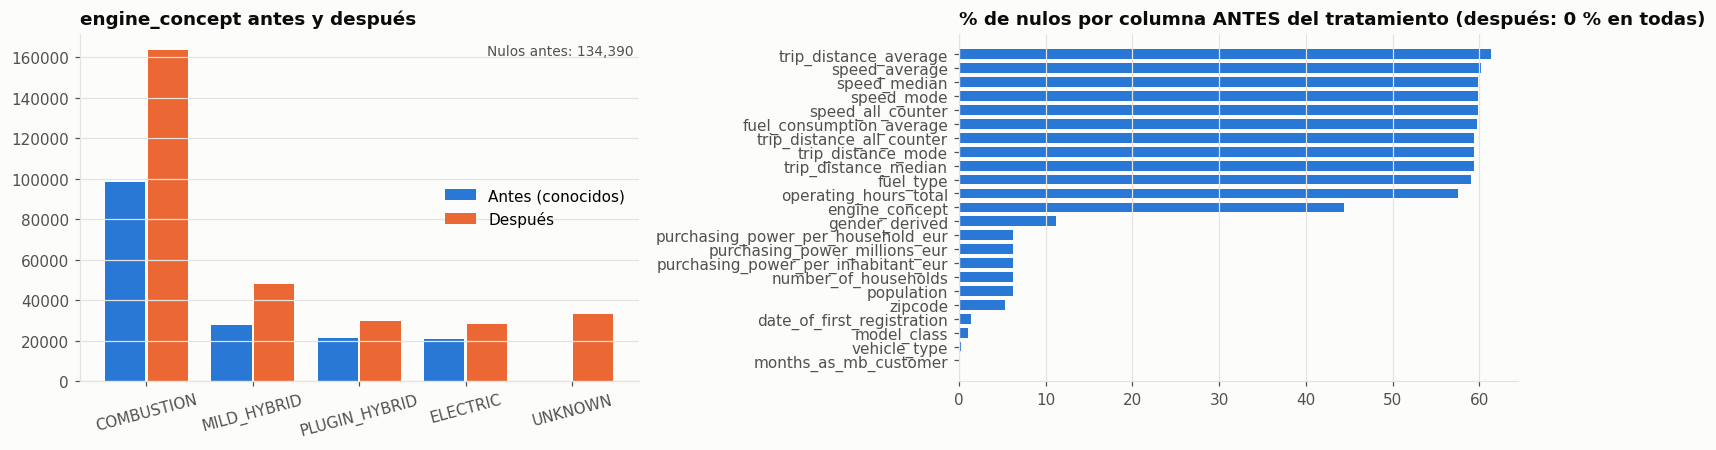

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
orden = ["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC", "UNKNOWN"]
a = raw.engine_concept.fillna("NULO (antes)").value_counts()
b = clean.engine_concept.value_counts().reindex(orden)
x = np.arange(len(orden))
ax = axes[0]
ax.bar(x - 0.2, raw.engine_concept.value_counts().reindex(orden).fillna(0), 0.38, color=ps.SERIES[0], label="Antes (conocidos)")
ax.bar(x + 0.2, b, 0.38, color=ps.SERIES[1], label="Después")
ax.set_xticks(x, orden, rotation=15); ax.set_title("engine_concept antes y después"); ax.legend()
ax.text(0.99, 0.97, f"Nulos antes: {raw.engine_concept.isna().sum():,}", transform=ax.transAxes, ha="right", va="top", fontsize=9, color=ps.INK_2)

ax = axes[1]
pct = (raw.isna().mean() * 100)
pct = pct[pct > 0].sort_values()
ax.barh(pct.index, pct.values, color=ps.SERIES[0], height=0.7)
ax.set_title("% de nulos por columna ANTES del tratamiento (después: 0 % en todas)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "01b_antes_despues.png"); plt.show()

### 5.2 Tabla resumen: cómo se ha tratado cada columna

In [33]:
TRATAMIENTO = {
    "client_id": ("Sin nulos", "Identificador. Sin cambios."),
    "vehicle_id": ("Sin nulos", "Identificador. Sin cambios."),
    "age_range": ("Sin nulos", "Sin cambios."),
    "gender_derived": ("Categoría UNKNOWN", "Nulo no aleatorio (más en usuarios secundarios y extremos de edad); dato inferido. No se imputa con la moda."),
    "model_series": ("Sin nulos", "Sin cambios. Se usa como pista para deducir otras columnas."),
    "vehicle_type": ("Categoría UNKNOWN", "Nombre comercial único: no reconstruible."),
    "model_class": ("Deducción validada", "Del nombre del coche (exacto o prefijo) con pureza mínima; si no hay evidencia, UNKNOWN."),
    "product_group": ("Sin nulos", "Sin cambios."),
    "engine_concept": ("Deducción validada", "Cascada: reglas EQ/e-de, nombre+año, nombre, serie+año, clase+año. Sin evidencia -> UNKNOWN (nunca 'combustión por defecto')."),
    "country_code": ("Sin nulos", "Sin cambios. Se usa como grupo para imputar la zona."),
    "fuel_type": ("Deducción validada", "Reglas validadas (eléctrico -> ELECTRIC; nombre diésel -> DIESEL o DIESEL,ELECTRIC) + mismo modelo con mismo motor. Gasolina vs gasolina plus no deducible -> UNKNOWN."),
    "date_of_first_registration": ("Mediana de la serie", "Mediana de fecha de los coches de la misma serie (validado). Fechas < 2000 tratadas como nulo."),
    "is_current_vehicle": ("Sin nulos", "Sin cambios."),
    "role": ("Sin nulos", "Sin cambios."),
    "role_type": ("Sin nulos", "Sin cambios."),
    "months_as_mb_customer": ("Mediana de grupo", "4 filas: mediana de clientes con el mismo nº de vehículos conectados."),
    "currently_connected_vehicles": ("Sin nulos", "Sin cambios."),
    "finance_leasing_status": ("Sin nulos", "Sin cambios."),
    "workshop_visits_warranty_goodwill": ("Sin nulos", "Sin cambios."),
    "consent_phone_communication_channel": ("Sin nulos", "Sin cambios."),
    "consent_epost_communication_channel": ("Sin nulos", "Sin cambios."),
    "consent_post_communication_channel": ("Sin nulos", "Sin cambios."),
    "purchasing_power_per_inhabitant_eur": ("Mediana del país", "Falta junto al resto de la zona. Se marca con socio_imputed."),
    "purchasing_power_per_household_eur": ("Mediana del país", "Idem."),
    "population": ("Mediana del país", "Idem. Los ceros (73 filas) eran falsos valores y se tratan como nulo."),
    "zipcode": ("Categoría UNKNOWN", "Identificador geográfico: no se inventa."),
    "trip_distance_average": ("Mediana por motorización", "Falta estructural (coche sin telemetría). Marca: has_trip_data."),
    "trip_distance_mode": ("Categoría NO_DATA", "Texto con una o varias modas."),
    "trip_distance_median": ("Mediana por motorización", "Idem. Marca: has_trip_data."),
    "trip_distance_all_counter": ("Relleno con 0", "Nº de mediciones: sin datos = 0."),
    "operating_hours_total": ("Mediana por año de matriculación", "Acumulado que crece con la edad. Marca: has_hours_data."),
    "fuel_consumption_average": ("0 eléctricos / mediana por clase", "Eléctrico no consume combustible. Marca: has_consumption_data."),
    "speed_average": ("Mediana por motorización", "Falta estructural. Marca: has_speed_data."),
    "speed_mode": ("Categoría NO_DATA", "Texto con una o varias modas."),
    "speed_median": ("Mediana por motorización", "Idem. Marca: has_speed_data."),
    "speed_all_counter": ("Relleno con 0", "Nº de mediciones: sin datos = 0."),
    "number_of_households": ("Mediana del país", "Idem zona. Los ceros se tratan como nulo."),
    "purchasing_power_millions_eur": ("Recalculado", "= pp por habitante × población / 1e6 (identidad verificada en los datos reales)."),
}
resumen = pd.DataFrame({
    "nulos_antes": raw.isna().sum(),
    "%_antes": (raw.isna().mean() * 100).round(2),
    "nulos_despues": clean[orig_cols].isna().sum(),
    "tratamiento": [TRATAMIENTO[c][0] for c in orig_cols],
    "detalle": [TRATAMIENTO[c][1] for c in orig_cols],
})
assert set(TRATAMIENTO) == set(orig_cols)
(ROOT / "reports").mkdir(exist_ok=True)
resumen.to_csv(ROOT / "reports" / "tratamiento_nulos_resumen.csv", index_label="columna")
pd.set_option("display.max_colwidth", 140)
resumen[resumen.nulos_antes > 0]

,nulos_antes,%_antes,nulos_despues,tratamiento,detalle
gender_derived,33923,11.20,0,Categoría UNKNOWN,Nulo no aleatorio (más en usuarios secundarios y extremos de edad); dato inferido. No se imputa con la moda.
vehicle_type,922,0.30,0,Categoría UNKNOWN,Nombre comercial único: no reconstruible.
model_class,3369,1.11,0,Deducción validada,"Del nombre del coche (exacto o prefijo) con pureza mínima; si no hay evidencia, UNKNOWN."
engine_concept,134390,44.38,0,Deducción validada,"Cascada: reglas EQ/e-de, nombre+año, nombre, serie+año, clase+año. Sin evidencia -> UNKNOWN (nunca 'combustión por defecto')."
fuel_type,178745,59.02,0,Deducción validada,"Reglas validadas (eléctrico -> ELECTRIC; nombre diésel -> DIESEL o DIESEL,ELECTRIC) + mismo modelo con mismo motor. Gasolina vs gasolina..."
date_of_first_registration,4182,1.38,0,Mediana de la serie,Mediana de fecha de los coches de la misma serie (validado). Fechas < 2000 tratadas como nulo.
months_as_mb_customer,4,0.00,0,Mediana de grupo,4 filas: mediana de clientes con el mismo nº de vehículos conectados.
purchasing_power_per_inhabitant_eur,19087,6.30,0,Mediana del país,Falta junto al resto de la zona. Se marca con socio_imputed.
purchasing_power_per_household_eur,19087,6.30,0,Mediana del país,Idem.
population,19014,6.28,0,Mediana del país,Idem. Los ceros (73 filas) eran falsos valores y se tratan como nulo.


### Indicadores nuevos que se añaden al CSV

| Columna | Significado |
|---|---|
| `model_class_imputed`, `engine_concept_imputed`, `fuel_type_imputed`, `registration_date_imputed` | `True` si el valor original faltaba y se ha deducido / imputado |
| `socio_imputed` | `True` si los datos de la zona (poder adquisitivo, población…) se han imputado con la mediana del país |
| `has_trip_data`, `has_speed_data`, `has_hours_data`, `has_consumption_data` | `True` si el coche **realmente** tenía ese bloque de telemetría |
| `has_telemetry` | `True` si tenía **algún** bloque. Filtrar por esta columna para analizar conducción |

### 5.3 Guardado del CSV limpio

In [34]:
DATA_DIR.mkdir(exist_ok=True)
OUT = DATA_DIR / "datos_limpios.csv"
clean.to_csv(OUT, index=False)
print(f"Guardado: {OUT}  ({OUT.stat().st_size / 1e6:.0f} MB)")
chk = pd.read_csv(OUT, low_memory=False, dtype={"zipcode": str})
print("Relectura -> filas:", len(chk), "· nulos totales:", int(chk.isna().sum().sum()))

Guardado: C:\Users\mario\Desktop\malakathon\data\datos_limpios.csv  (128 MB)


Relectura -> filas: 302850 · nulos totales: 0


### 5.4 Resumen de decisiones

| Situación | Qué hicimos |
|---|---|
| El dato se **puede deducir** de otras columnas (`model_class`, `engine_concept`, `fuel_type`) | Cascada de reglas **validada** escondiendo valores conocidos; solo se acepta una regla si es fiable |
| El dato **no se puede deducir con fiabilidad** | Se deja `UNKNOWN`: **no se inventa** (`vehicle_type`, `zipcode`, `gender_derived`, parte de motor/combustible) |
| El nulo **es información** (género) | Categoría propia, sin imputar con la moda |
| Falta una **variable numérica** de contexto | Mediana de un **grupo comparable** (país, serie, motorización) y se marca con un indicador |
| La falta es **estructural** (telemetría) | Se registra la ausencia real con `has_*` y se rellena con el criterio que tiene sentido para cada tipo de columna (0, `NO_DATA`, mediana) |
| Un dato es **función exacta de otros** (`purchasing_power_millions_eur`) | Se recalcula, no se imputa |

**Consecuencias para el clustering:** las columnas de telemetría rellenadas **no** deben alimentar el modelo sin tener en cuenta `has_telemetry`;
`UNKNOWN` en motor/combustible puede tratarse como categoría propia o excluirse.